# Exploratory Data Analysis: Pneumonia Detection from Chest X-rays

**Goal of this notebook:** understand the NIH ChestX-ray14 dataset before training a model.
Every analysis here supports one of three later decisions:

1. **How to split the data** into training and validation sets.
2. **What the model may be used for**, which goes into the FDA document (who it works for, where it fails).
3. **How to prepare the images** before they go into the network.

**Two data sources:**

| Table | Rows | Used for |
|---|---|---|
| `all_xray_df` (`Data_Entry_2017.csv`) | 112,120 images | All statistics: demographics, labels, patients |
| `data_sample` (`sample_labels.csv`) | 5,606 images | Pixel-level analysis only (these images are on disk) |

## 1. Setup

In [2]:
# Data handling
import os
from glob import glob
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Image reading (used in the pixel-level section)
from skimage.io import imread

## 2. Load the data

The notebook runs inside `notebooks/`, so the data folder is one level up (`../data`).

In [3]:
DATA_DIR = '../data'

all_xray_df = pd.read_csv(os.path.join(DATA_DIR, 'Data_Entry_2017.csv'))
data_sample = pd.read_csv(os.path.join(DATA_DIR, 'sample_labels.csv'))

print('Full dataset:', all_xray_df.shape)
print('Sample:      ', data_sample.shape)

Full dataset: (112120, 12)
Sample:       (5606, 11)


In [4]:
# A notebook cell only shows its last line, so use display() to see both tables
display(all_xray_df.sample(3, random_state=0))
display(data_sample.sample(3, random_state=0))

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
10539,00002723_010.png,No Finding,10,2723,58,F,PA,2992,2991,0.143,0.143,NaN
39718,00010377_002.png,No Finding,2,10377,66,M,AP,2500,2048,0.168,0.168,NaN
29391,00007651_000.png,Cardiomegaly,0,7651,71,M,PA,2048,2500,0.168,0.168,NaN


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImageWidth,OriginalImageHeight,OriginalImagePixelSpacing_x,OriginalImagePixelSpacing_y
731,00003838_000.png,No Finding,0,3838,052Y,F,PA,2048,2500,0.168,0.168
1569,00008127_001.png,No Finding,1,8127,032Y,F,PA,2048,2500,0.168,0.168
5081,00027001_001.png,No Finding,1,27001,057Y,F,AP,3056,2544,0.139,0.139


## 3. Data cleaning

### 3.1 Missing values and column names

In [5]:
# Count empty cells per column
print('Full dataset:')
print(all_xray_df.isna().sum())
print()
print('Sample:')
print(data_sample.isna().sum())

Full dataset:
Image Index                         0
Finding Labels                      0
Follow-up #                         0
Patient ID                          0
Patient Age                         0
Patient Gender                      0
View Position                       0
OriginalImage[Width                 0
Height]                             0
OriginalImagePixelSpacing[x         0
y]                                  0
Unnamed: 11                    112120
dtype: int64

Sample:
Image Index                    0
Finding Labels                 0
Follow-up #                    0
Patient ID                     0
Patient Age                    0
Patient Gender                 0
View Position                  0
OriginalImageWidth             0
OriginalImageHeight            0
OriginalImagePixelSpacing_x    0
OriginalImagePixelSpacing_y    0
dtype: int64


**Finding:** the full table has one completely empty column, `Unnamed: 11`. It comes from a
trailing comma at the end of each line in the CSV file, so pandas reads an extra empty column.
It holds no information, so it is dropped.

The two tables also use different names for the image-size columns. They are renamed so the
same code works on both tables.

In [6]:
# Drop the empty column
all_xray_df = all_xray_df.drop(columns=['Unnamed: 11'])

# Use the same column names as the sample table
all_xray_df = all_xray_df.rename(columns={
    'OriginalImage[Width': 'OriginalImageWidth',
    'Height]': 'OriginalImageHeight',
    'OriginalImagePixelSpacing[x': 'OriginalImagePixelSpacing_x',
    'y]': 'OriginalImagePixelSpacing_y',
})

# Check: both tables should now have identical columns
print(list(all_xray_df.columns) == list(data_sample.columns))

True


### 3.2 Patient age

Two problems to handle:

1. In the sample, age is stored as text such as `060Y` (`Y` = years). It must be converted to a number.
2. Both tables contain impossible ages (above 100 years), which are data entry errors.

**Decision:** keep these images and set only the age to missing (`NaN`). The error is in the age field,
not in the image or its label, and pneumonia images are too rare to throw any away. The age is not
replaced by the mean, because that would invent data and distort the age statistics.

In [7]:
# Check the unit letter at the end of each sample age (Y = years, M = months, D = days)
print(data_sample['Patient Age'].str[-1].value_counts())

Patient Age
Y    5604
M       1
D       1
Name: count, dtype: int64


In [8]:
# Convert '060Y' -> 60: drop the last character, then convert text to a number.
# The original column is kept unchanged.
data_sample['Age'] = data_sample['Patient Age'].str[:-1].astype(int)

# Count impossible ages before fixing them (these numbers go into the FDA document)
n_bad_full = (all_xray_df['Patient Age'] > 100).sum()
n_bad_sample = (data_sample['Age'] > 100).sum()
print('Images with age > 100, full dataset:', n_bad_full)
print('Images with age > 100, sample:      ', n_bad_sample)

# Show the affected rows in the full dataset
display(all_xray_df[all_xray_df['Patient Age'] > 100])

Images with age > 100, full dataset: 16
Images with age > 100, sample:       1


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImageWidth,OriginalImageHeight,OriginalImagePixelSpacing_x,OriginalImagePixelSpacing_y
20852,00005567_000.png,Effusion|Pneumonia,0,5567,412,M,AP,3056,2544,0.139,0.139
46965,00011973_002.png,Edema,2,11973,414,M,AP,3056,2544,0.139,0.139
48284,00012238_010.png,No Finding,10,12238,148,M,PA,2992,2991,0.143,0.143
55742,00013950_000.png,No Finding,0,13950,148,M,PA,2964,2939,0.143,0.143
58650,00014520_026.png,Infiltration|Mass,26,14520,150,M,PA,2992,2991,0.143,0.143
62929,00015558_000.png,No Finding,0,15558,149,M,PA,2992,2991,0.143,0.143
74884,00018366_044.png,Pneumothorax,44,18366,152,F,PA,2302,2991,0.143,0.143
78795,00019346_000.png,Infiltration,0,19346,151,F,PA,2678,2774,0.143,0.143
84810,00020900_002.png,No Finding,2,20900,411,M,AP,3056,2544,0.139,0.139
85404,00021047_002.png,Mass|Pleural_Thickening,2,21047,412,M,AP,3056,2544,0.139,0.139


In [9]:
# Set impossible ages to missing. The mask is built from the same table it filters.
all_xray_df.loc[all_xray_df['Patient Age'] > 100, 'Patient Age'] = np.nan
data_sample.loc[data_sample['Age'] > 100, 'Age'] = np.nan

# Check: the maximum age should now be plausible
print('Max age, full dataset:', all_xray_df['Patient Age'].max())
print('Max age, sample:      ', data_sample['Age'].max())

Max age, full dataset: 95.0
Max age, sample:       94.0


## 4. Is the sample representative of the full dataset?

The pixel-level analysis uses only the sample, so first check that the sample looks like the full
dataset. **Proportions** are compared, not counts, because the full table is about 20 times larger.

### 4.1 Sex

                  all  sample
Patient Gender               
M               0.565   0.559
F               0.435   0.441


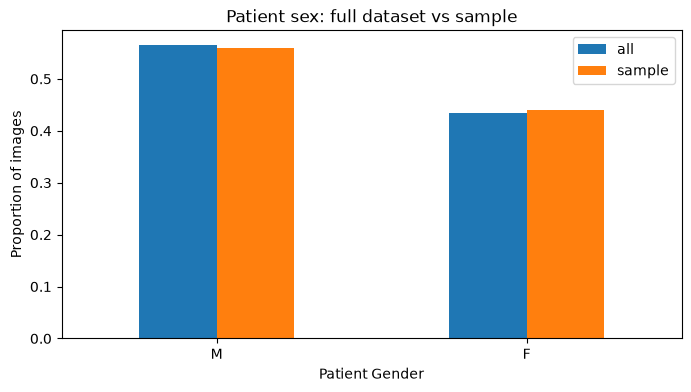

In [10]:
sex = pd.DataFrame({
    'all':    all_xray_df['Patient Gender'].value_counts(normalize=True),
    'sample': data_sample['Patient Gender'].value_counts(normalize=True),
})
print(sex.round(3))

sex.plot.bar(rot=0, figsize=(8, 4))
plt.ylabel('Proportion of images')
plt.title('Patient sex: full dataset vs sample')
plt.show()

### 4.2 View position

- **PA** (posterior-anterior): patient standing, standard chest X-ray in the radiology department.
- **AP** (anterior-posterior): usually a portable X-ray at the bedside, for patients too ill to stand.

               all  sample
View Position             
PA             0.6   0.605
AP             0.4   0.395


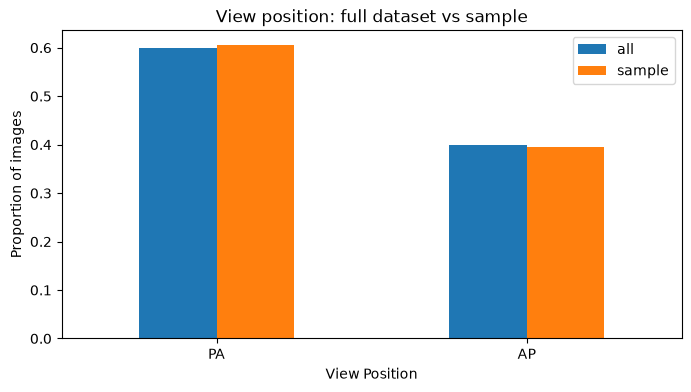

In [11]:
view = pd.DataFrame({
    'all':    all_xray_df['View Position'].value_counts(normalize=True),
    'sample': data_sample['View Position'].value_counts(normalize=True),
})
print(view.round(3))

view.plot.bar(rot=0, figsize=(8, 4))
plt.ylabel('Proportion of images')
plt.title('View position: full dataset vs sample')
plt.show()

### 4.3 Age

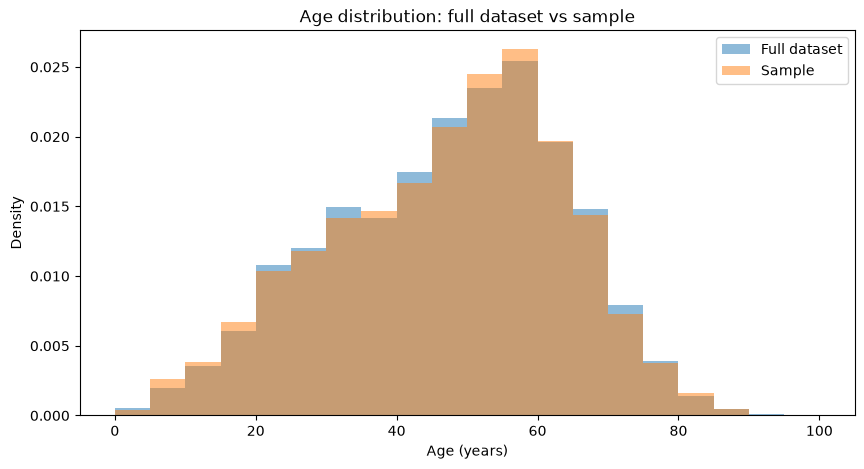

           full  sample
count  112120.0  5606.0
mean       46.9    46.8
std        16.8    17.4
min         1.0     1.0
25%        35.0    35.0
50%        49.0    49.0
75%        59.0    59.0
max       414.0   411.0


In [10]:
# Same bin edges for both tables (0, 5, 10, ..., 100) so the bars line up.
# density=True makes the two tables comparable despite their different sizes.
bins = np.arange(0, 105, 5)

plt.figure(figsize=(10, 5))
plt.hist(all_xray_df['Patient Age'].dropna(), bins=bins, density=True, alpha=0.5, label='Full dataset')
plt.hist(data_sample['Age'].dropna(),         bins=bins, density=True, alpha=0.5, label='Sample')
plt.legend()
plt.xlabel('Age (years)')
plt.ylabel('Density')
plt.title('Age distribution: full dataset vs sample')
plt.show()

print(pd.DataFrame({
    'full':   all_xray_df['Patient Age'].describe(),
    'sample': data_sample['Age'].describe(),
}).round(1))

### 4.4 Pneumonia share

In [11]:
# .str.contains() gives True/False per row; the mean of True/False is the fraction of True
pneu_full = all_xray_df['Finding Labels'].str.contains('Pneumonia').mean()
pneu_sample = data_sample['Finding Labels'].str.contains('Pneumonia').mean()
print(f'Pneumonia share, full dataset: {pneu_full:.2%}')
print(f'Pneumonia share, sample:       {pneu_sample:.2%}')

Pneumonia share, full dataset: 1.28%
Pneumonia share, sample:       1.11%


### Findings so far

*Fill in the blanks with your own numbers from the outputs above.*

- **Sample vs full dataset:** the sample has nearly the same distribution of sex,
  view position , age (median __ vs __ years) and pneumonia share (1.28% vs 1.11%).
  The sample is representative, so it can be used for the pixel-level analysis.
- **Data quality:** the CSV contained one completely empty column (`Unnamed: 11`), which was dropped.
  __ images in the full dataset and __ in the sample had an impossible age (> 100 years); their age was set
  to missing and the images were kept.
- **Note:** the comparison above shows that the *sample matches the full data*. It does not say whether the
  data is balanced. In this project, "imbalance" refers to the target, pneumonia vs no pneumonia, which is
  analysed in section 5.

## 5. Disease labels (full dataset)

`Finding Labels` stores several diseases in one text string, for example `Effusion|Infiltration`.
Counting that column directly counts *combinations*, not diseases:

In [12]:
# Top combinations, for illustration only
all_xray_df['Finding Labels'].value_counts().head(10)

Finding Labels
No Finding                  60361
Infiltration                 9547
Atelectasis                  4215
Effusion                     3955
Nodule                       2705
Pneumothorax                 2194
Mass                         2139
Effusion|Infiltration        1603
Atelectasis|Infiltration     1350
Consolidation                1310
Name: count, dtype: int64

### 5.1 One column per disease ✏️ *your task*

Create one True/False column per disease, so each disease can be counted on its own.

**Hints**
- Get the list of all diseases: split every label string at `|`, collect all pieces, keep the unique ones.
  `all_xray_df['Finding Labels'].str.split('|')` gives a list per row.
- Remove `'No Finding'` from that list; it is not a disease.
- Loop over the diseases: `all_xray_df[disease] = all_xray_df['Finding Labels'].str.contains(disease)`
- Do the same for `data_sample`.

In [17]:
# TODO: build the list of diseases
all_labels = all_xray_df['Finding Labels'].str.split('|').explode().unique()

all_labels = [label for label in all_labels if label != 'No Finding']


# one True/False column per disease, in both tables

for disease in all_labels:
    all_xray_df[disease] = all_xray_df['Finding Labels'].str.contains(disease)
    data_sample[disease] = data_sample['Finding Labels'].str.contains(disease)

print(all_xray_df.shape)
all_xray_df[['Finding Labels'] + all_labels].head(3)

(112120, 25)


,Finding Labels,Cardiomegaly,Emphysema,Effusion,Hernia,Infiltration,Mass,Nodule,Atelectasis,Pneumothorax,Pleural_Thickening,Pneumonia,Fibrosis,Edema,Consolidation
0,Cardiomegaly,True,False,False,False,False,False,False,False,False,False,False,False,False,False
1,Cardiomegaly|Emphysema,True,True,False,False,False,False,False,False,False,False,False,False,False,False
2,Cardiomegaly|Effusion,True,False,True,False,False,False,False,False,False,False,False,False,False,False


### 5.2 How often does each disease occur? 

Count the images per disease and plot them as a horizontal bar chart, sorted.
Also print the **number and percentage of pneumonia images**. This is the class imbalance the model
must deal with.

*Hint:* `all_xray_df[all_labels].sum()` adds up the True values per column.

<Axes: >

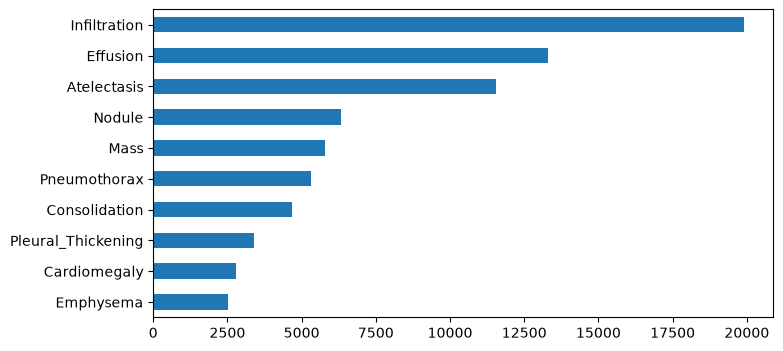

In [21]:
disease_counts = all_xray_df[all_labels].sum().sort_values(ascending=False).head(10)

disease_counts.sort_values(ascending=True).plot.barh(figsize=(8, 4))

### 5.3 Number of diseases per image ✏️ *your task*



In [24]:
all_xray_df['n_labels']  = all_xray_df[all_labels].sum(axis=1)


n_labels
0    60361
1    30963
2    14306
3     4856
4     1247
5      301
6       67
7       16
8        1
9        2
Name: count, dtype: int64


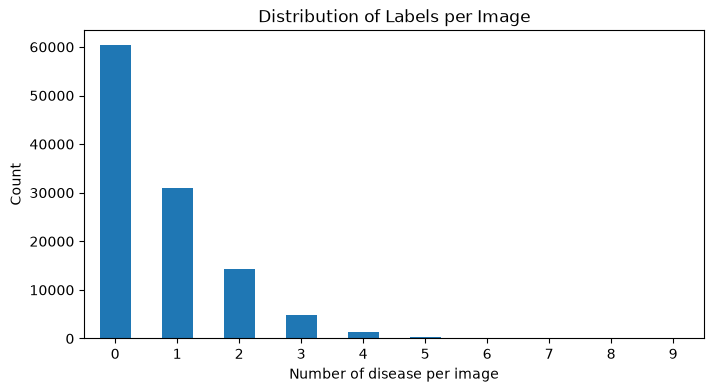

In [26]:
counts = all_xray_df['n_labels'].value_counts().sort_index()
print(counts)

counts.plot.bar(rot=0, figsize=(8, 4))
plt.xlabel('Number of disease per image')
plt.ylabel('Count')
plt.title('Distribution of Labels per Image')
plt.show()

## 6. Pneumonia in detail (full dataset)

From here on, compare **pneumonia images** with **all other images**.

### 6.1 Which other diseases appear together with pneumonia? ✏️ *your task*

Keep only the pneumonia rows, then count how often each other disease appears in them.
Show it as a percentage of all pneumonia images.

This tells you what the model may confuse with pneumonia, and it goes into the FDA document.

In [46]:
other_labels = [label for label in all_labels if label != 'Pneumonia']

print(all_xray_df[all_xray_df['Pneumonia']][other_labels].mean().sort_values(ascending=False))


Infiltration          0.422781
Edema                 0.237596
Effusion              0.187980
Atelectasis           0.183089
Consolidation         0.085954
Mass                  0.049616
Nodule                0.048917
Pleural_Thickening    0.033543
Cardiomegaly          0.028651
Pneumothorax          0.028651
Emphysema             0.016073
Fibrosis              0.007687
Hernia                0.002096
dtype: float64


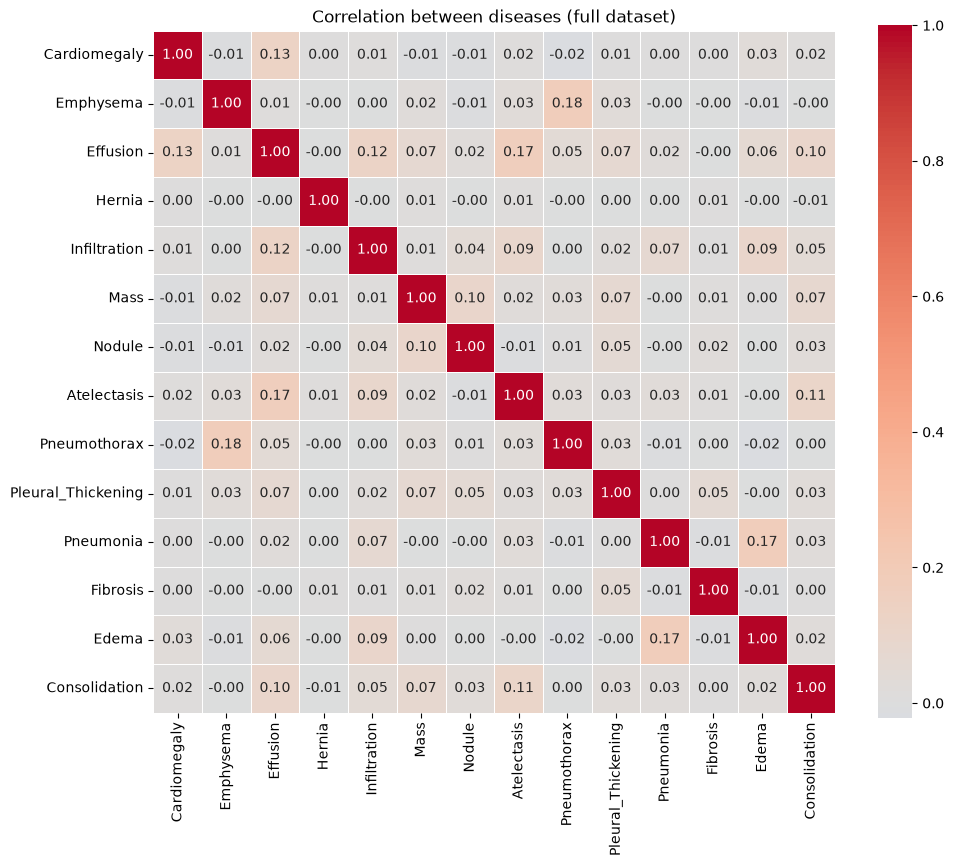

In [51]:
corr = all_xray_df[all_labels].astype(int).corr()
# Hide the upper triangle and the diagonal (always 1)


plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='coolwarm', center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5)
plt.title('Correlation between diseases (full dataset)')
plt.show()

### 6.2 Pneumonia by age, sex and view position ✏️ *your task*

- **Age:** two histograms (pneumonia vs no pneumonia) on one plot, `density=True`.
- **Sex:** proportion of male and female among pneumonia images vs all others.
- **View position:** the **pneumonia rate within PA images** and **within AP images**.

If the rate is very different between PA and AP, the model could learn a shortcut
("AP image, so probably sick") instead of looking at the lungs.

                pneumonia  no pneumonia
Patient Gender                         
M                   0.586         0.565
F                   0.414         0.435


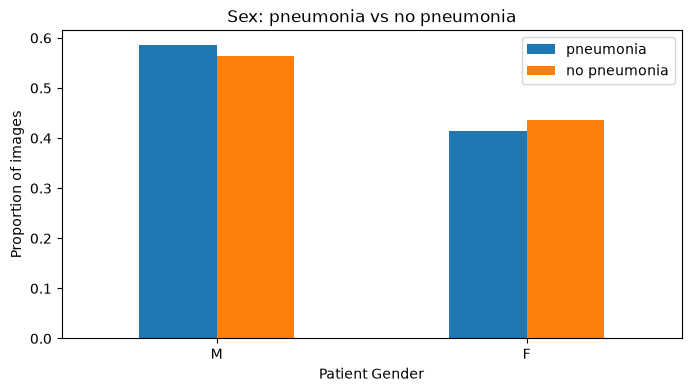

In [62]:
pneu = all_xray_df['Pneumonia']          # True/False per row, used as a filter below

sex = pd.DataFrame({
    'pneumonia':    all_xray_df[pneu]['Patient Gender'].value_counts(normalize=True),
    'no pneumonia': all_xray_df[~pneu]['Patient Gender'].value_counts(normalize=True),
})
print(sex.round(3))

sex.plot.bar(rot=0, figsize=(8, 4))
plt.ylabel('Proportion of images')
plt.title('Sex: pneumonia vs no pneumonia')
plt.show()


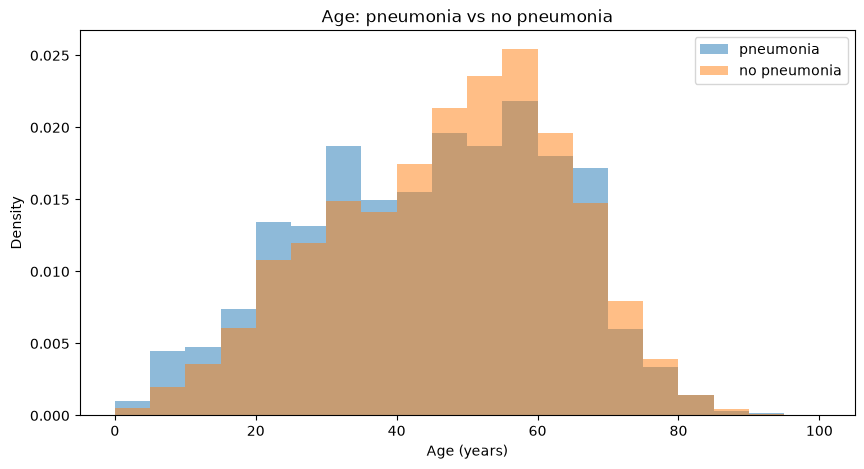

              count  mean   std  min   25%   50%   75%   max
Pneumonia                                                   
False      110674.0  46.9  16.6  1.0  35.0  49.0  59.0  95.0
True         1430.0  44.7  17.6  2.0  31.0  46.0  59.0  90.0


In [63]:
bins = np.arange(0, 105, 5)

plt.figure(figsize=(10, 5))
plt.hist(all_xray_df[pneu]['Patient Age'].dropna(),  bins=bins, density=True, alpha=0.5, label='pneumonia')
plt.hist(all_xray_df[~pneu]['Patient Age'].dropna(), bins=bins, density=True, alpha=0.5, label='no pneumonia')
plt.legend()
plt.xlabel('Age (years)')
plt.ylabel('Density')
plt.title('Age: pneumonia vs no pneumonia')
plt.show()

print(all_xray_df.groupby('Pneumonia')['Patient Age'].describe().round(1))


View Position
AP    1.79
PA    0.94
Name: Pneumonia, dtype: float64


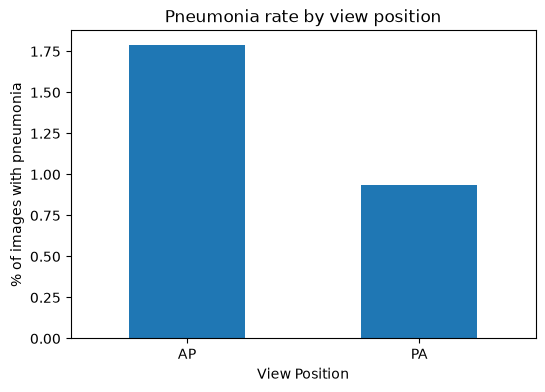

In [64]:
rate = all_xray_df.groupby('View Position')['Pneumonia'].mean() * 100
print(rate.round(2))

rate.plot.bar(rot=0, figsize=(6, 4))
plt.ylabel('% of images with pneumonia')
plt.title('Pneumonia rate by view position')
plt.show()

## 7. Patients (full dataset)

### 7.1 Images per patient ✏️ *your task*

How many images does one patient have? Show the distribution and the maximum.



**Why it matters:** if images of the same patient end up in both training and validation, the model is
tested on patients it has already seen, and the validation score is too optimistic. The split must
therefore be done **by patient**, not by image.

In [72]:
images_per_patient = all_xray_df['Patient ID'].value_counts()
images_per_patient

Patient ID
10007    184
13670    173
15530    158
12834    157
13993    143
        ... 
30800      1
30802      1
30803      1
30804      1
30805      1
Name: count, Length: 30805, dtype: int64

### 7.2 Pneumonia patients 

How many **different patients** have at least one pneumonia image?
Compare with the number of pneumonia images.

In [74]:
all_xray_df[all_xray_df['Pneumonia']]['Patient ID'].nunique()

1008

## 8. Pixel-level analysis (sample only)

Load images from the sample and compare pixel intensity distributions between
**pneumonia**, **no finding**, and a look-alike disease such as **infiltration**.

First find where each sample image is stored on disk.

In [75]:
# Map each image file name to its full path.
# Adjust the pattern if your sample images are stored in a different folder.
image_paths = {os.path.basename(p): p for p in glob(os.path.join(DATA_DIR, 'sample', '**', '*.png'), recursive=True)}
print('Images found on disk:', len(image_paths))

data_sample['path'] = data_sample['Image Index'].map(image_paths)
print('Sample rows without an image file:', data_sample['path'].isna().sum())

Images found on disk: 5606
Sample rows without an image file: 0


### 8.1 Look at a few images 

Show 3 pneumonia images and 3 no-finding images side by side.

*Hint:* `plt.subplots(2, 3)` and `ax.imshow(imread(path), cmap='gray')`.

In [78]:
data_sample.columns

Index(['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID',
       'Patient Age', 'Patient Gender', 'View Position', 'OriginalImageWidth',
       'OriginalImageHeight', 'OriginalImagePixelSpacing_x',
       'OriginalImagePixelSpacing_y', 'Age', 'Cardiomegaly', 'Emphysema',
       'Effusion', 'Hernia', 'Infiltration', 'Mass', 'Nodule', 'Atelectasis',
       'Pneumothorax', 'Pleural_Thickening', 'Pneumonia', 'Fibrosis', 'Edema',
       'Consolidation', 'path'],
      dtype='str')

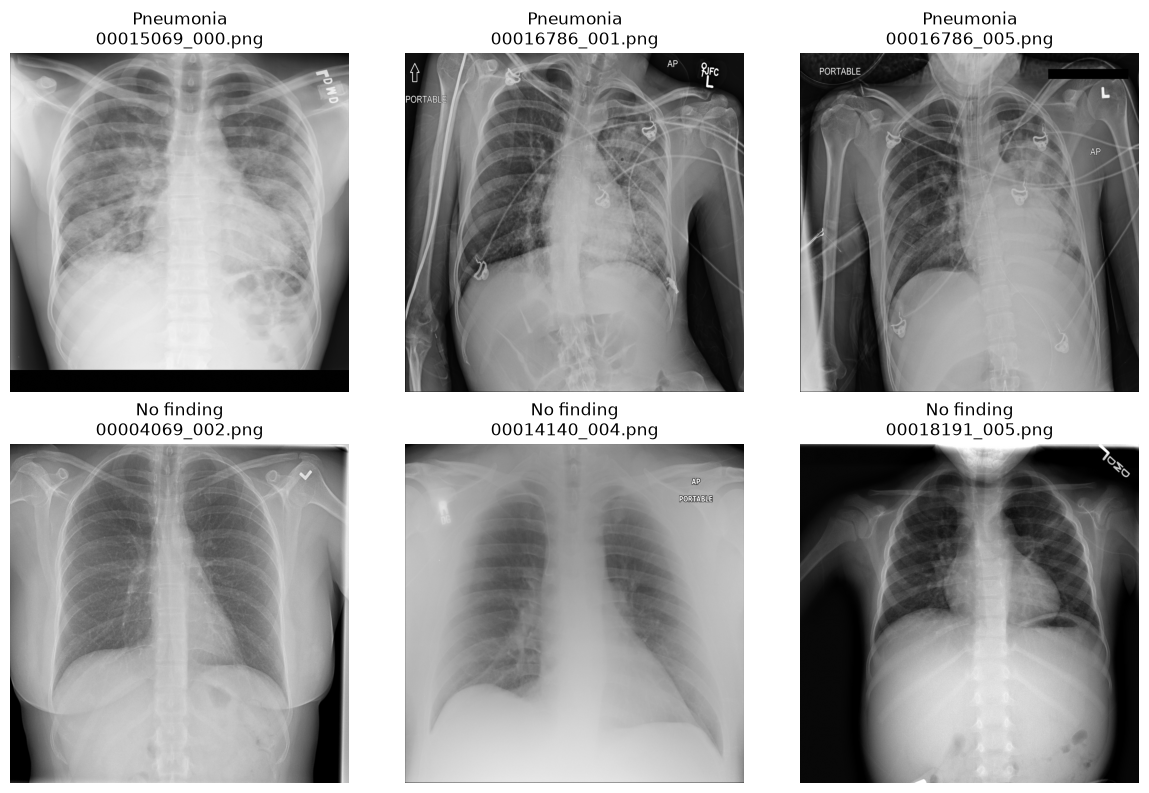

In [86]:
pneumonia_imgs = data_sample[data_sample['Pneumonia']].sample(3, random_state=0)
healthy_imgs = data_sample[data_sample['Finding Labels'] == 'No Finding'].sample(3, random_state=0)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for row_nr, (group_name, group) in enumerate([('Pneumonia', pneumonia_imgs), ('No finding', healthy_imgs)]):
    for col_nr, (_, img_row) in enumerate(group.iterrows()):
        ax = axes[row_nr, col_nr]
        ax.imshow(imread(img_row['path']), cmap='gray')
        ax.set_title(f"{group_name}\n{img_row['Image Index']}")
        ax.axis('off')

plt.tight_layout()
plt.show()

### 8.2 Intensity histograms 

For about 20 images per group, collect all pixel values and plot one histogram per group
on the same axes (`density=True`, `alpha=0.5`).

*Hints*
- `imread(path).flatten()` turns an image into one long list of pixel values.
- Many pixels are pure black background. Consider ignoring very dark pixels (e.g. below 20),
  otherwise the background dominates the histogram.
- Some images may load with more than one channel. Check `img.shape`; if it has 3 dimensions,
  keep only the first channel: `img[:, :, 0]`.

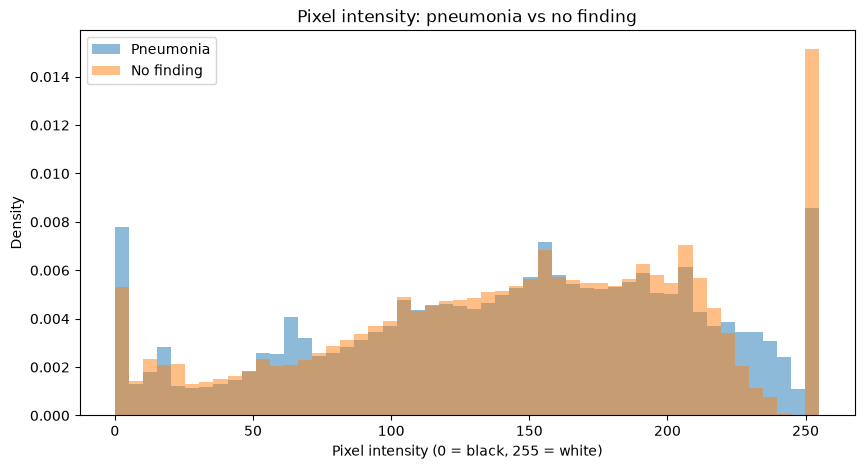

In [87]:
# Pick 20 images per group
pneumonia_paths = data_sample[data_sample['Pneumonia']]['path'].head(20)
healthy_paths   = data_sample[data_sample['Finding Labels'] == 'No Finding']['path'].head(20)

# Collect the pixel values of the pneumonia images
pneumonia_pixels = []
for path in pneumonia_paths:
    img = imread(path)
    pneumonia_pixels.extend(img.flatten())

# Collect the pixel values of the healthy images
healthy_pixels = []
for path in healthy_paths:
    img = imread(path)
    healthy_pixels.extend(img.flatten())

# Plot both histograms on top of each other
plt.figure(figsize=(10, 5))
plt.hist(pneumonia_pixels, bins=50, density=True, alpha=0.5, label='Pneumonia')
plt.hist(healthy_pixels,   bins=50, density=True, alpha=0.5, label='No finding')
plt.legend()
plt.xlabel('Pixel intensity (0 = black, 255 = white)')
plt.ylabel('Density')
plt.title('Pixel intensity: pneumonia vs no finding')
plt.show()

## 9. Conclusions and consequences for model training

**Dataset**
- 112,120 frontal chest X-rays from 30,805 patients.
- 56.5% male, 43.5% female. Median age 49 years (range 1–95 after cleaning).
- 60% PA (standing, radiology department) and 40% AP (mostly portable, bedside).
- Data quality: one empty column was dropped; 16 images in the full dataset had an impossible
  age (148–414 years) and 2 sample images had ages in months/days. Their age was set to missing,
  the images were kept.
- The sample (5,606 images) matches the full dataset in sex, view position, age and pneumonia share,
  so it is representative for the pixel-level analysis.

**Pneumonia**
- 1,431 pneumonia images (1.28% of all images) from 1,008 patients, about 1.4 images per patient.
  The dataset is therefore strongly imbalanced.
- Pneumonia rarely appears alone. Most frequent co-occurring findings among pneumonia images:
  Infiltration (42%), Edema (24%), Effusion (19%), Atelectasis (18%).
- Age: pneumonia patients are slightly younger (median 46 vs 49 years), with relatively more
  cases between 5 and 35 years.
- Sex: slightly more male (58.6% vs 56.5%). The difference is small.
- View position: the pneumonia rate is about twice as high in AP images (1.79%) as in PA images
  (0.94%). Example images show "PORTABLE" markers, ECG leads and tubes in pneumonia cases.

**Pixel level**
- The intensity histograms of pneumonia and no-finding images overlap almost completely.
  Pneumonia images show slightly more bright pixels (220–250), which fits with opaque areas in the
  lungs, but the difference is small and based on only 20 images per group.
- Brightness alone cannot separate the classes; the model must learn shapes and patterns,
  which is why a CNN is used.

**Consequences for training**
- **Split by patient:** no patient may appear in both training and validation, otherwise the model
  could recognise the person instead of the disease (one patient has 184 images).
- **Training set:** balanced (about 50% pneumonia), so the model sees enough positive cases.
- **Validation set:** realistic pneumonia share, so the measured performance reflects real use.
- **Metric:** not accuracy (always predicting "no pneumonia" would already give 98.7%);
  precision, recall and F1 instead.
- **View position:** keep the PA/AP mix similar in training and validation, because AP images
  are more often positive and could become a shortcut.
- **Limitations for the FDA document:** pneumonia overlaps strongly with infiltration and edema,
  and labels were extracted from reports by NLP, so some labels are wrong.